# 10 · Error analysis (test split)

Where and why the final model (DistilRoBERTa + similarity features, frozen in 08, evaluated once in 09) is wrong on
the 6,182 test petitions. Nothing here changes a model or a setting; it explains the results.

1. **Where the errors are:** which classes are confused with which.
2. **Does the review flag catch them?** Errors against the 0.75 confidence threshold.
3. **Does duplicate retrieval rescue missed duplicates?** If the classifier calls a duplicate "published", is the
   correct open petition still in the top-5 list the moderator sees?
4. **Why:** a sample of 105 errors read one by one and sorted into reason categories.

**Input:** `data/processed/predictions/final_test_predictions.parquet` and `retrieval_test_ranks.parquet` (from 09),
`petitions.parquet`, and `reports/error_analysis_coded.csv` (the 105 sampled errors with a category and a note,
assigned by reading each petition's title and text, its closest open petition and, for duplicates, the petition the
moderator linked).

**Output:** `reports/error_analysis_summary.csv`, `reports/figures/error_categories_test.png`.

In [1]:
import sys
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent                      # this notebook runs inside notebooks/
sys.path.insert(0, str(ROOT / "src"))
from preprocess import CLASSES

DATA, REPORTS = ROOT / "data" / "processed", ROOT / "reports"
SEED = 42
BLUE, INK, MUTED, GRID = "#2a78d6", "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({"font.size": 10, "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": MUTED,
                     "axes.grid": True, "grid.color": GRID, "axes.axisbelow": True, "text.color": INK,
                     "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED, "figure.dpi": 110,
                     "savefig.dpi": 200, "savefig.bbox": "tight"})

final = pd.read_parquet(DATA / "predictions" / "final_test_predictions.parquet")
ranks = pd.read_parquet(DATA / "predictions" / "retrieval_test_ranks.parquet").set_index("query_id")
wrong = final[final["label"] != final["predicted"]]
assert len(final) == 6_182
print(f"{len(wrong):,} errors out of {len(final):,} test petitions ({len(wrong) / len(final):.1%})")

1,485 errors out of 6,182 test petitions (24.0%)


## 1. Where the errors are

The most frequent (true → predicted) pairs, and the error rate of each true class.

In [2]:
pairs = wrong.groupby(["label", "predicted"]).size().sort_values(ascending=False)
top_pairs = pairs.head(12).rename("errors").reset_index()
top_pairs["share of all errors"] = (top_pairs["errors"] / len(wrong)).round(3)
per_class = pd.DataFrame({"petitions": final["label"].value_counts(), "errors": wrong["label"].value_counts()}).reindex(CLASSES)
per_class["error rate"] = (per_class["errors"] / per_class["petitions"]).round(3)
print(per_class.to_string(), "\n")
top_pairs

                   petitions  errors  error rate
label                                           
published               3017     248       0.082
duplicate               1737     432       0.249
irrelevant               505     277       0.549
no-action                563     339       0.602
honours                   33       8       0.242
already-happening        103      94       0.913
local                    224      87       0.388 



,label,predicted,errors,share of all errors
0,duplicate,published,286,0.193
1,published,duplicate,190,0.128
2,no-action,duplicate,170,0.114
3,no-action,published,103,0.069
4,duplicate,no-action,95,0.064
5,irrelevant,local,90,0.061
6,irrelevant,published,74,0.050
7,irrelevant,duplicate,69,0.046
8,local,irrelevant,56,0.038
9,no-action,irrelevant,53,0.036


## 2. Does the review flag catch the errors?

A petition is flagged when the final model's confidence is below 0.75 (frozen in 08).

In [3]:
right = final[final["label"] == final["predicted"]]
print(f"flagged: {wrong['flagged'].mean():.1%} of the errors, {right['flagged'].mean():.1%} of the correct predictions")
print(f"confident errors (not flagged): {(~wrong['flagged']).sum():,} = {(~wrong['flagged']).sum() / len(final):.1%} of all test petitions")
bands = pd.cut(final["confidence"], [0, 0.5, 0.75, 0.9, 1.0], labels=["< 0.50", "0.50-0.75", "0.75-0.90", "> 0.90"])
pd.DataFrame({"petitions": bands.value_counts().sort_index(),
              "accuracy": (final["label"] == final["predicted"]).groupby(bands, observed=False).mean().round(3)})

flagged: 72.0% of the errors, 28.3% of the correct predictions
confident errors (not flagged): 416 = 6.7% of all test petitions


,petitions,accuracy
confidence,,
< 0.50,716,0.415
0.50-0.75,1682,0.614
0.75-0.90,1551,0.821
> 0.90,2233,0.938


## 3. Does duplicate retrieval rescue missed duplicates?

The moderator sees both the predicted outcome and the top-5 most similar open petitions (hybrid retrieval, 09).

In [4]:
def in_top5(frame):
    queries = frame[frame["id"].isin(ranks.index)]
    return (ranks.loc[queries["id"], "hybrid_open"] <= 5).mean(), len(queries)

missed = wrong[(wrong["label"] == "duplicate") & (wrong["predicted"] == "published")]
for name, frame in [("duplicates predicted as published", missed),
                    ("duplicates predicted as any other class", wrong[wrong["label"] == "duplicate"]),
                    ("all test duplicates", final[final["label"] == "duplicate"])]:
    share, n = in_top5(frame)
    print(f"{name}: correct open petition in the top 5 for {share:.1%} of {n:,}")

duplicates predicted as published: correct open petition in the top 5 for 96.8% of 283
duplicates predicted as any other class: correct open petition in the top 5 for 93.5% of 428
all test duplicates: correct open petition in the top 5 for 94.1% of 1,728


## 4. Why: 105 errors read one by one

**The sample.** From the 1,485 errors, petitions were drawn at random (seed 42) in proportion to each true class's
errors, with at least 5 per class, so rare classes are also covered: 105 errors.

**How they were coded.** Each error was read: title and text, the closest open petition at decision time (MiniLM)
and, for duplicates, the petition the moderator linked. It was then put in one category. The categories follow the
official rejection rules: *irrelevant* = not something the UK Government or Parliament is directly responsible for;
*local* = a matter for a local authority; *no-action* = no clear request for action; *already-happening* = the
Government is already doing it; *honours* = honours or appointments.

| Category | Meaning |
|---|---|
| duplicate missed: clear match | an open petition asks the same thing; the classifier missed it |
| duplicate missed: loose link | the moderator linked a petition that is only broadly related |
| false duplicate: related topic | an open petition on the same topic exists, but the request differs, so it was published |
| who is responsible | deciding needs knowledge of who is responsible (FA, BBC, councils, NHS trusts, devolved governments) |
| needs current policy knowledge | deciding needs knowledge of what the Government is already doing or planning |
| vague or no clear request | the petition asks for no specific action (or asks the Government not to act) |
| honours and appointments | calls to remove or replace ministers, or confidence votes, count as appointments |
| questionable label | a very similar petition got the predicted outcome, or the official label is hard to explain |
| no clear reason | a clear request that the model simply got wrong (low confidence) |

The coding is a judgement made by reading; each row keeps a short note so it can be checked.

In [5]:
coded = pd.read_csv(REPORTS / "error_analysis_coded.csv")
counts = wrong["label"].value_counts().reindex(CLASSES)
allocation = np.maximum(5, np.round(100 * counts / counts.sum())).astype(int)
sample = pd.concat([wrong[wrong["label"] == c].sample(allocation[c], random_state=SEED) for c in CLASSES])
assert list(sample["id"]) == list(coded["id"])       # the coded file is exactly this sample
print("sample per true class:", allocation.to_dict(), "| total", allocation.sum())

ORDER = ["duplicate missed: clear match", "duplicate missed: loose link", "false duplicate: related topic", "who is responsible",
         "needs current policy knowledge", "vague or no clear request", "honours and appointments", "questionable label",
         "no clear reason"]
summary = coded.groupby("category").agg(errors=("id", "size"), flagged=("flagged", "mean")).reindex(ORDER)
summary["share"] = (summary["errors"] / len(coded)).round(3)
summary["flagged"] = summary["flagged"].round(2)
summary.to_csv(REPORTS / "error_analysis_summary.csv")
summary

sample per true class: {'published': 17, 'duplicate': 29, 'irrelevant': 19, 'no-action': 23, 'honours': 5, 'already-happening': 6, 'local': 6} | total 105


,errors,flagged,share
category,,,
duplicate missed: clear match,21,0.67,0.200
duplicate missed: loose link,7,1.00,0.067
false duplicate: related topic,12,0.92,0.114
who is responsible,22,0.64,0.210
needs current policy knowledge,10,0.80,0.095
vague or no clear request,15,0.67,0.143
honours and appointments,5,0.80,0.048
questionable label,10,0.40,0.095
no clear reason,3,1.00,0.029


In [6]:
pd.crosstab(coded["category"], coded["label"]).reindex(index=ORDER, columns=CLASSES, fill_value=0)

label,published,duplicate,irrelevant,no-action,honours,already-happening,local
category,,,,,,,
duplicate missed: clear match,0,21,0,0,0,0,0
duplicate missed: loose link,0,7,0,0,0,0,0
false duplicate: related topic,12,0,0,0,0,0,0
who is responsible,0,0,16,0,0,0,6
needs current policy knowledge,0,0,0,4,0,6,0
vague or no clear request,0,0,0,15,0,0,0
honours and appointments,0,0,0,0,5,0,0
questionable label,2,1,3,4,0,0,0
no clear reason,3,0,0,0,0,0,0


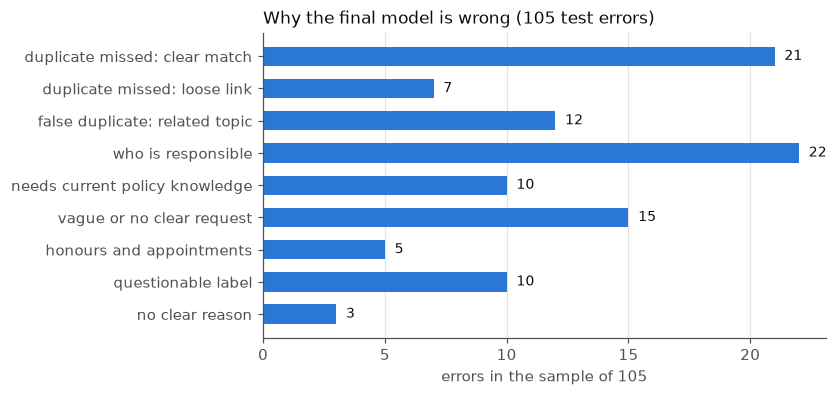

In [7]:
fig, ax = plt.subplots(figsize=(6.6, 3.6))
y = np.arange(len(ORDER))[::-1]
ax.barh(y, summary["errors"], color=BLUE, height=0.6)
for yi, n in zip(y, summary["errors"]):
    ax.text(n + 0.4, yi, str(n), va="center", fontsize=9, color=INK)
ax.set_yticks(y, ORDER)
ax.set_xlabel("errors in the sample of 105")
ax.grid(axis="y", visible=False)
ax.set_title("Why the final model is wrong (105 test errors)", loc="left", fontsize=11)
fig.savefig(REPORTS / "figures" / "error_categories_test.png")
plt.show()

## 5. Two examples per category

In [8]:
pd.set_option("display.max_colwidth", 70)
examples = coded.groupby("category", sort=False).head(2).set_index("category").loc[ORDER]
examples[["label", "predicted", "confidence", "title", "note"]]

,label,predicted,confidence,title,note
category,,,,,
duplicate missed: clear match,duplicate,published,0.869711,Requiring drivers to stop and report any road traffic collisions i...,linked petition is the closest open one
duplicate missed: clear match,duplicate,published,0.773866,National Workplace Heat Alert System with Enforceable Work Restric...,same ask as the linked maximum-temperature petition
duplicate missed: loose link,duplicate,published,0.489674,Create a New Independent Skilled Worker Visa Route,linked work-permit petition is only broadly related
duplicate missed: loose link,duplicate,no-action,0.573805,Change For children with Special Educational Needs.,linked assessment petition is only broadly related
false duplicate: related topic,published,duplicate,0.576454,Extend Paid Maternity Leave to 18 Months to Support Child Developm...,"related open petition on maternity pay, different ask"
false duplicate: related topic,published,duplicate,0.588816,Reduce the age that the cbt can be done for 50cc to 14 years old,"related open petition on driving age, different ask"
who is responsible,irrelevant,published,0.901219,Ask the FA to improve England team preparation with year-round tra...,"the FA decides, not the Government"
who is responsible,irrelevant,published,0.931081,Create a free and accessible NHS period tracking app,an NHS app; moderators treat it as outside direct Government respo...
needs current policy knowledge,no-action,duplicate,0.716338,The 6/7/26 should be a nationwide bank holiday for the England gam...,one-off bank holiday at short notice; needs knowledge of Governmen...


## Summary

- **1,485 errors (24.0%), spread very unevenly:** published 8.2% wrong, duplicate 24.9%, local 38.8%, irrelevant
  54.9%, no-action 60.2%, already-happening 91.3%.
- **The biggest confusion is duplicate ↔ published:** 286 + 190 errors, a third of all errors. Next comes
  no-action → duplicate (170).
- **The review flag catches most errors:** 72.0% of the errors are flagged, against 28.3% of the correct predictions.
  Accuracy rises from 41.5% (confidence below 0.50) to 93.8% (above 0.90). Confident errors are 416 petitions,
  6.7% of the test set.
- **Retrieval rescues missed duplicates:** for 96.8% of the duplicates predicted as published, the correct open
  petition is in the top-5 list, so the moderator would still see it. The two tasks cover each other.
- **Why, from 105 errors read one by one:**

| Reason | Errors | Share |
|---|---|---|
| Duplicate missed: 21 clear matches (the top-5 list shows them), 7 loose links to only broadly related petitions | 28 | 27% |
| Who is responsible: the FA, the BBC, private companies, councils, NHS trusts, devolved governments | 22 | 21% |
| Vague request, no clear action (no-action) | 15 | 14% |
| False duplicate: same topic as an open petition, but a different request | 12 | 11% |
| Needs knowledge of current policy (already-happening, some no-action) | 10 | 10% |
| Questionable label: a very similar petition got the predicted outcome, or the label is hard to explain | 10 | 10% |
| Honours and appointments; no clear reason | 5 + 3 | 8% |

- In the questionable-label group, the model is usually **confident** (only 40% flagged), as expected when the label,
  not the model, is the odd one out.
- **What it means:** most errors need knowledge that is not in the petition text (who is responsible for what, what
  the Government is already doing), or reflect fine or inconsistent lines in moderation. A bigger text model would
  not fix these; outside knowledge would. These points go to the report's limitations and future work.
- **Caution:** the coding is one reader's judgement on a sample of 105. It shows the main patterns, not exact rates.
